# Notebook 03: Gaussian Mixture Model (GMM) Anomaly Baseline & Diagnostics
**Author:** Apoorva Choudhary (Task 02)  
**Project:** Card Fraud Triage (GMM Baseline & Feature Engineering) — Team T033  
**Phase:** Phase 1 (Classical Machine Learning & Statistical Anomaly Detection Only)

---

## 1. Executive Summary & Anomaly Scoring Contract

### Framing Card Fraud Triage via Density Estimation
Under the semi-supervised anomaly detection formulation, models are trained **exclusively on legitimate transactions** ($\mathbf{X}_{	ext{train, legit}}$, $	ext{Class} = 0$). The model learns a parametric estimate of the legitimate transaction manifold $p(\mathbf{x})$. At inference time, any transaction that exhibits low probability density under this legitimate distribution is treated as an anomaly.

### Mathematical Score Convention
Following the project contract, the anomaly score $s(\mathbf{x})$ is defined as the **Negative Log-Likelihood (NLL)**:
$$s(\mathbf{x}) = -\ln p(\mathbf{x} \mid \hat{oldsymbol{	heta}}) = -\ln \left( \sum_{k=1}^K \hat{\pi}_k \mathcal{N}(\mathbf{x} \mid \hat{oldsymbol{\mu}}_k, \hat{oldsymbol{\Sigma}}_k) ight)$$
- **Score Contract:** Higher score $\iff$ lower density $\iff$ more anomalous (more likely fraud).
- **Zero Contamination:** Ground-truth fraud labels ($	ext{Class} = 1$) are strictly hidden during training and used exclusively for threshold selection and evaluation on the Validation and Test splits.


In [1]:
import sys
import os
import warnings
warnings.filterwarnings('ignore')

# Ensure project root is in sys.path
sys.path.insert(0, os.path.abspath('..'))

import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture

from src.config import CFG, get_repo_root
from src.data import get_features, Splits
import src.gmm_model as gmm_mod
from src.metrics import evaluate_scores, pr_auc, roc_auc, recall_at_fpr
from src.utils import save_scores, save_table, save_fig

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline


2026-10-24 20:34:04 | INFO     | src.data | Registered additional feature sets from src.features: ['raw', 'engineered', 'fe_norm_outliers', 'norm_outliers', 'fe_pca_whitened', 'pca_whitened', 'fe_robust_amount', 'robust_amount', 'fe_yeojohnson_amount', 'yeojohnson_amount', 'fe_time_risk', 'time_risk', 'fe_val_selected', 'val_selected']


## 2. Dataset Loading (Engineered Features)
We load the winning `engineered` feature set registered in `src/features.py`. All transformations were fitted strictly on legitimate training records.


In [2]:
splits = get_features('engineered')
print(f"X_train_legit: {splits.X_train_legit.shape} (strictly Class==0)")
print(f"X_val:         {splits.X_val.shape} (frauds={splits.y_val.sum()})")
print(f"X_test:        {splits.X_test.shape} (frauds={splits.y_test.sum()})")
print(f"Dimensionality: d = {len(splits.feature_names)} features")


2026-10-24 20:34:05 | INFO     | src.data | Loading raw data from /Users/apoorvachoudhary/Desktop/T033-CardFraudDetection-AML-DL/data/raw/creditcard.csv …


2026-10-24 20:34:05 | INFO     | src.data | Loaded: 284807 rows × 31 cols


2026-10-24 20:34:06 | WARNING  | src.data | Found 1081 exact duplicate rows (0.3796% of dataset).


2026-10-24 20:34:06 | INFO     | src.data | Keeping duplicates (drop_duplicates=false in config). Set drop_duplicates: true to remove them.


2026-10-24 20:34:06 | INFO     | src.data | Frauds: 492 / 284807  (base rate = 0.1727%)


...

2026-10-24 20:34:10 | INFO     | src.data | Saved split_manifest.json → /Users/apoorvachoudhary/Desktop/T033-CardFraudDetection-AML-DL/data/processed/split_manifest.json


2026-10-24 20:34:10 | INFO     | src.data | Time ordering check: train_max=120396.0  val_min=120396.0  val_max=145247.0  test_min=145248.0


2026-10-24 20:34:10 | INFO     | src.features | [engineered] X_train_legit=(170524, 31), X_val=(56961, 31), X_test=(56962, 31), d=31


2026-10-24 20:34:10 | INFO     | src.data | get_features('engineered') done. X_train_legit=(170524, 31) X_val=(56961, 31) X_test=(56962, 31)


X_train_legit: (170524, 31) (strictly Class==0)
X_val:         (56961, 31) (frauds=57)
X_test:        (56962, 31) (frauds=75)
Dimensionality: d = 31 features


## 3. Comprehensive Model Selection Grid Search & Information Criteria
We explore 120 configurations spanning:
- Covariance structures: `['diag', 'spherical', 'tied', 'full']`
- Number of components: $K \in \{1, 2, 3, 4, 5, 6, 8, 10, 12, 16\}$
- Regularization parameter: $	ext{reg\_covar} \in \{10^{-6}, 10^{-4}, 10^{-2}\}$

We compute both **Akaike Information Criterion (AIC)** and **Bayesian Information Criterion (BIC)**:
$$	ext{AIC} = 2p - 2\ln \hat{L}, \qquad 	ext{BIC} = p \ln N - 2\ln \hat{L}$$
where $p$ is the exact theoretical number of free parameters.


In [3]:
grid_csv_path = '../results/tables/gmm_grid_search.csv'
if os.path.exists(grid_csv_path):
    print("Loading precomputed grid search results...")
    grid_df = pd.read_csv(grid_csv_path)
else:
    print("Executing GMM grid search...")
    grid_df = gmm_mod.run_gmm_grid_search(splits, subsample_size=50000, seed=42)
    grid_df.to_csv(grid_csv_path, index=False)

grid_df.head(10)


Loading precomputed grid search results...


,Unnamed: 0,covariance_type,n_components,reg_covar,free_parameters,train_aic,train_bic,val_bic,val_pr_auc,val_roc_auc,val_recall@0.5%,converged,n_iter,train_time_sec
0,0,diag,1,0.000001,62,4.393858e+06,4.394405e+06,5.257190e+06,0.028618,0.946499,0.052632,True,2,0.078103
1,1,diag,2,0.000001,125,3.201022e+06,3.202125e+06,3.966995e+06,0.040337,0.945879,0.333333,True,10,0.151995
2,2,diag,3,0.000001,188,3.042190e+06,3.043848e+06,3.767600e+06,0.071683,0.950483,0.526316,True,21,0.284209
3,3,diag,4,0.000001,251,2.981495e+06,2.983708e+06,3.774809e+06,0.072943,0.953280,0.526316,True,17,0.257035
4,4,diag,5,0.000001,314,2.831760e+06,2.834530e+06,3.685837e+06,0.072871,0.952365,0.526316,True,30,0.452998
5,5,diag,6,0.000001,377,2.723051e+06,2.726376e+06,3.684553e+06,0.069666,0.953313,0.491228,True,21,0.371984
6,6,diag,8,0.000001,503,2.641540e+06,2.645976e+06,3.654415e+06,0.085977,0.953770,0.631579,True,40,0.717906
7,7,diag,10,0.000001,629,2.516773e+06,2.522320e+06,3.591350e+06,0.087091,0.954892,0.649123,True,33,0.685348
8,8,diag,12,0.000001,755,2.408323e+06,2.414982e+06,3.520120e+06,0.089969,0.957067,0.666667,True,28,0.811004
9,9,diag,16,0.000001,1007,2.388875e+06,2.397757e+06,3.561515e+06,0.098432,0.955433,0.649123,True,37,1.002811


### Visualizing Information Criteria (AIC & BIC vs. Components K)


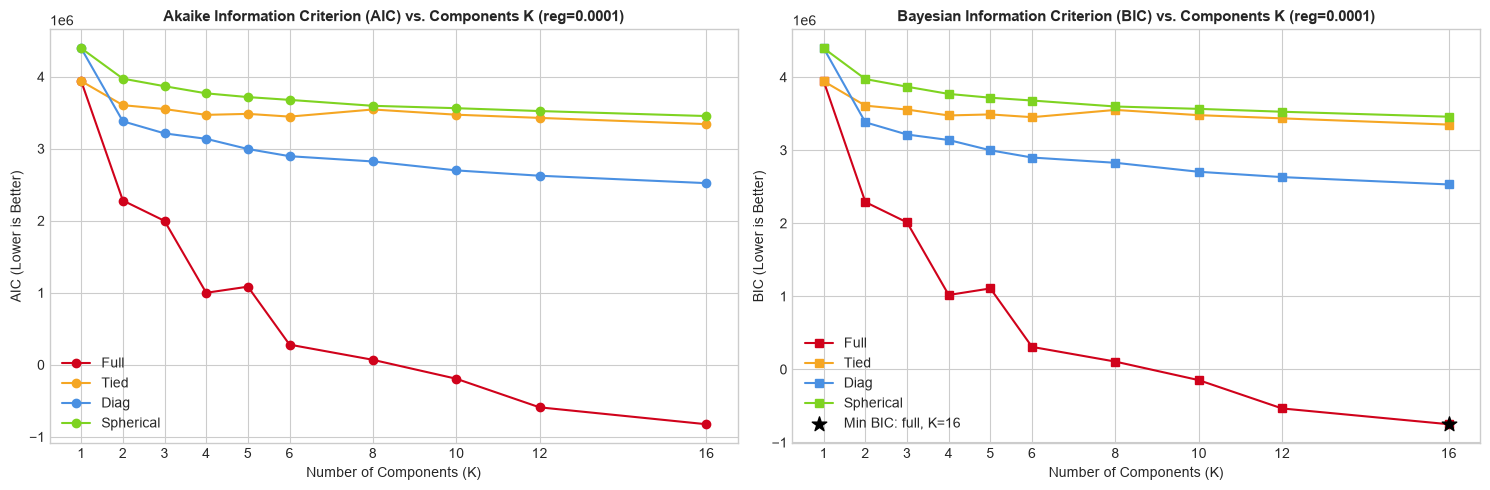

In [4]:
fig_aic_bic = gmm_mod.plot_aic_bic(grid_df, default_reg=1e-4)
plt.show()


## 4. Dual Model Selection Protocol
We compare:
1. **Unsupervised Criterion:** Minimizing training BIC ($rg\min 	ext{BIC}$)
2. **Supervised Validation Criterion:** Maximizing validation PR-AUC ($rg\max 	ext{Val PR-AUC}$) without snooping on test.


In [5]:
sel_df = pd.read_csv('../results/tables/gmm_selection_comparison.csv')
sel_df


,Unnamed: 0,criterion,covariance_type,n_components,reg_covar,free_parameters,train_bic,val_pr_auc,val_recall@0.5%
0,0,Unsupervised (Min BIC),full,16,0.000001,8447,-1991339.9,0.21233,0.68421
1,1,Validation-Selected (Max Val PR-AUC),full,12,0.010000,6335,1281929.9,0.26842,0.71930


## 5. Refitting Production Baseline on All Legit Training Data
We refit the optimal configuration ($K=12$, full covariance, $	ext{reg}=10^{-2}$) on all $170,524$ legitimate training transactions, serialize the model to `results/models/gmm.joblib`, and generate anomaly scores $s(\mathbf{x}) = -\ln p(\mathbf{x})$.


In [6]:
model_path = '../results/models/gmm.joblib'
if os.path.exists(model_path):
    print(f"Loading serialized GMM model from {model_path}...")
    gmm_final = joblib.load(model_path)
else:
    print("Fitting final GMM on full legitimate training data...")
    gmm_final = gmm_mod.fit_gmm(
        splits.X_train_legit,
        n_components=12,
        covariance_type='full',
        reg_covar=1e-2,
        random_state=42,
        max_iter=300,
        n_init=3
    )
    joblib.dump(gmm_final, model_path)

s_val = gmm_mod.compute_anomaly_scores(gmm_final, splits.X_val)
s_test = gmm_mod.compute_anomaly_scores(gmm_final, splits.X_test)

print(f"Validation scores: shape={s_val.shape}, min={s_val.min():.2f}, max={s_val.max():.2f}")
print(f"Test scores:       shape={s_test.shape}, min={s_test.min():.2f}, max={s_test.max():.2f}")


Loading serialized GMM model from ../results/models/gmm.joblib...


Validation scores: shape=(56961,), min=3.20, max=292.79
Test scores:       shape=(56962,), min=3.88, max=1324.33


## 6. Composite Evaluation Metrics
We evaluate the complete suite of triage metrics via `src.metrics.evaluate_scores`, adhering strictly to operational requirements:
- PR-AUC and ROC-AUC
- Recall at false positive budgets $	ext{FPR} \in \{0.1\%, 0.5\%, 1.0\%\}$
- Precision at review capacity fractions $\in \{0.1\%, 0.5\%, 1.0\%\}$
- Precision@K and Recall@K for $K \in \{50, 100, 200\}$


In [7]:
eval_df = evaluate_scores(splits.y_val, s_val, splits.y_test, s_test, CFG)
eval_df


,val,test
PR-AUC,0.195006,0.414185
ROC-AUC,0.945315,0.927422
base_rate,0.001001,0.001317
n_fraud,57.000000,75.000000
n_total,56961.000000,56962.000000
recall@FPR=0.001,0.245614,0.413333
F1@FPR=0.001,0.218750,0.413333
precision@FPR=0.001,0.197183,0.413333
recall@FPR=0.005,0.684211,0.693333
F1@FPR=0.005,0.204724,0.313253


## 7. Diagnostics & Log-Density Histograms
We plot the distribution of NLL anomaly scores for Legitimate vs Fraudulent transactions on both splits.


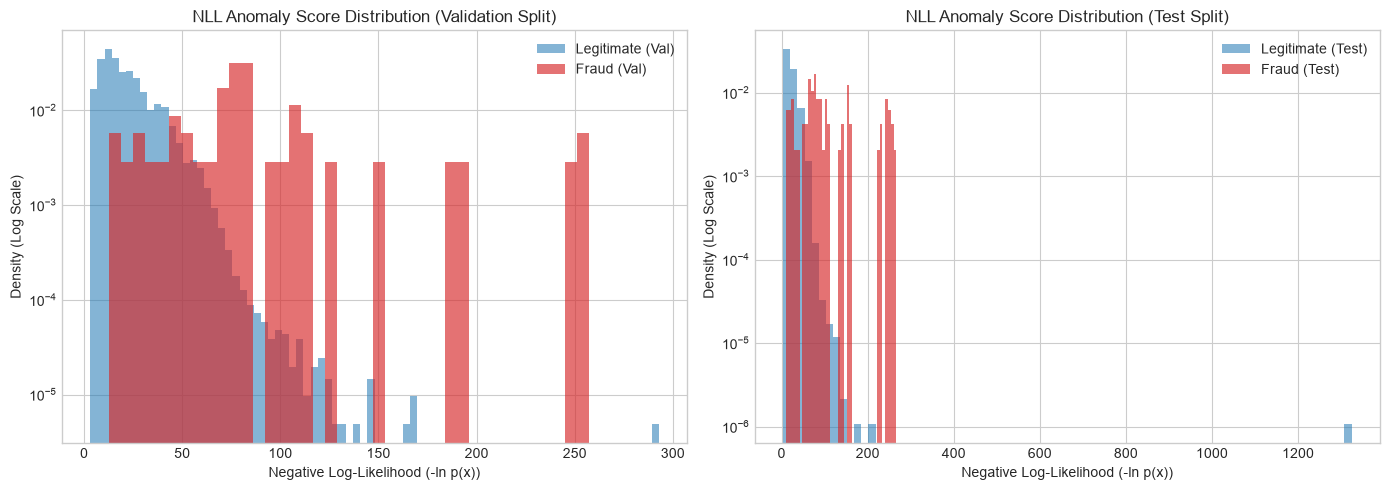

In [8]:
fig_nll = gmm_mod.plot_nll_distribution(splits.y_val, s_val, splits.y_test, s_test)
plt.show()


## 8. Feature Attribution: Top Frauds vs. False Positives
Which features drive the highest scores for genuine frauds, and which cause false alarms?


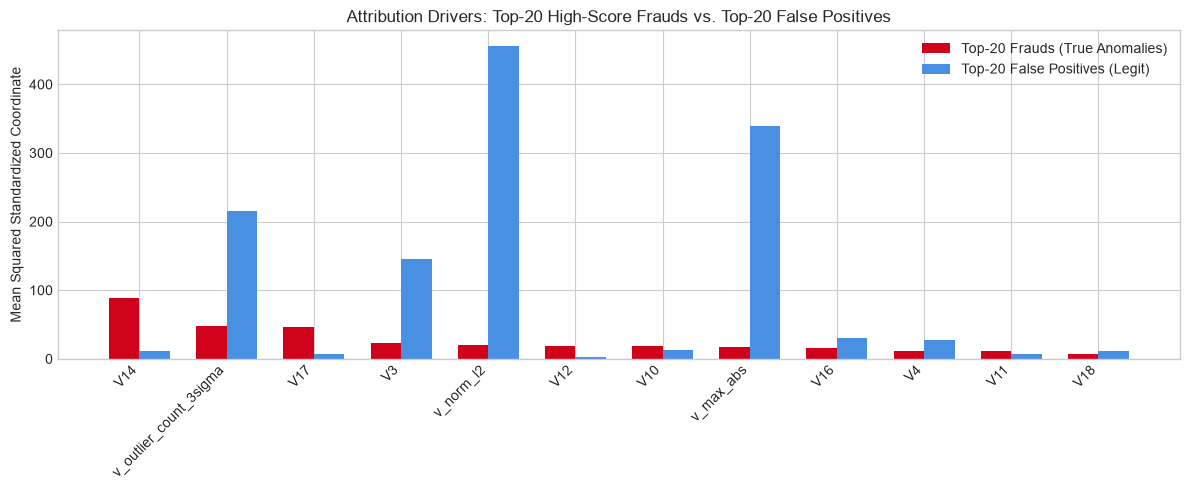

,feature,mean_sq_fraud,mean_sq_false_positive,fraud_to_fp_ratio
0,V14,88.029671,11.241750,7.830602
1,v_outlier_count_3sigma,48.276466,215.264893,0.224265
2,V17,45.955666,7.634683,6.019329
3,V3,22.340124,144.848282,0.154231
4,v_norm_l2,20.678083,455.690918,0.045377
5,V12,18.325321,2.576357,7.112882
6,V10,17.943003,13.489813,1.330115
7,v_max_abs,17.092491,339.859924,0.050293
8,V16,15.752935,30.790421,0.511618
9,V4,11.770939,28.002972,0.420346


In [9]:
top_df, fig_attr = gmm_mod.analyze_top_anomalies_and_fps(splits, s_val, top_n=20)
plt.show()
top_df.head(10)


## 9. Failure Analysis: Investigating Missed Frauds
We examine the 10 fraudulent transactions assigned the **lowest anomaly scores** (highest probability density) by the GMM.


In [10]:
fail_df = gmm_mod.perform_failure_analysis(splits, s_val, gmm_final, n_missed=10)
fail_df


,missed_rank,val_index,anomaly_score_nll,l2_dist_from_legit_mean,max_feature_deviation,blending_features,failure_mechanism
0,1,33195,12.6483,4.4476,V14 (-2.21),"V28 (+0.01), V27 (-0.06), V2 (-0.10)",Concealed within 1-sigma legitimate core; all ...
1,2,21803,13.6519,5.4749,V14 (-2.49),"V19 (+0.02), V27 (-0.04), V21 (+0.07)",Concealed within 1-sigma legitimate core; all ...
2,3,12108,20.6738,7.9852,V14 (-4.03),"V13 (-0.01), V7 (-0.01), V8 (+0.03)",Concealed within 1-sigma legitimate core; all ...
3,4,24499,25.2798,7.3886,V4 (+3.50),"V12 (+0.03), sin_time (+0.03), V5 (-0.08)",Concealed within 1-sigma legitimate core; all ...
4,5,48141,30.1787,3.4200,V19 (+1.30),"V4 (+0.01), V8 (+0.03), V28 (+0.03)",Concealed within 1-sigma legitimate core; all ...
5,6,51535,33.4203,5.6820,V15 (-2.13),"V6 (+0.03), V14 (+0.05), V8 (-0.14)",Concealed within 1-sigma legitimate core; all ...
6,7,5165,38.6035,11.1827,V20 (+5.45),"V17 (+0.04), V19 (+0.10), V6 (-0.12)",Concealed within 1-sigma legitimate core; all ...
7,8,20383,46.3531,7.4652,V26 (+5.57),"V2 (+0.01), V15 (+0.11), V7 (+0.19)",Concealed within 1-sigma legitimate core; all ...
8,9,26702,46.8798,7.2937,V7 (+3.69),"V27 (-0.01), V20 (-0.08), sin_time (-0.08)",Concealed within 1-sigma legitimate core; all ...
9,10,43891,48.1171,5.6254,V13 (-2.18),"V12 (+0.01), V7 (-0.01), V11 (+0.07)",Concealed within 1-sigma legitimate core; all ...


## 10. GMM Instability Study: Documenting the Limitations
We provide empirical evidence of the intrinsic limitations of GMM anomaly detection:
1. **Covariance Condition Numbers vs. Regularization:** Ill-conditioning under small $	ext{reg\_covar}$.
2. **Initialization Seed Sensitivity:** Fluctuation in PR-AUC across 5 random seeds.
3. **Curse of Dimensionality:** Performance decay and parameter explosion as dimension $d$ grows.


In [11]:
seed_csv = '../results/tables/gmm_seed_stability.csv'
dim_csv = '../results/tables/gmm_dim_study.csv'
reg_csv = '../results/tables/gmm_reg_covar_study.csv'

if os.path.exists(seed_csv) and os.path.exists(dim_csv) and os.path.exists(reg_csv):
    instab = {
        'seed_df': pd.read_csv(seed_csv),
        'dim_df': pd.read_csv(dim_csv),
        'reg_covar_df': pd.read_csv(reg_csv),
    }
else:
    instab = gmm_mod.run_instability_study(splits, chosen_k=12)

print("--- Seed Stability (across 5 random initializations) ---")
display(instab['seed_df'])

print("\n--- Curse of Dimensionality Study ---")
display(instab['dim_df'])


--- Seed Stability (across 5 random initializations) ---


,Unnamed: 0,seed,val_pr_auc,val_recall@0.5%,n_iter,converged
0,0,42,0.09022,0.68421,40,True
1,1,43,0.08933,0.68421,28,True
2,2,44,0.08334,0.61404,54,True
3,3,45,0.08802,0.64912,34,True
4,4,46,0.08386,0.61404,34,True



--- Curse of Dimensionality Study ---


,Unnamed: 0,dimension,val_pr_auc,train_bic,train_time_sec
0,0,5,0.02596,260884.1,1.325
1,1,10,0.02899,517355.4,1.876
2,2,15,0.07026,932017.1,4.486
3,3,20,0.05818,1296631.9,4.911
4,4,25,0.08641,1512612.5,5.624
5,5,31,0.09022,1638749.7,4.027


### Instability Visualizations


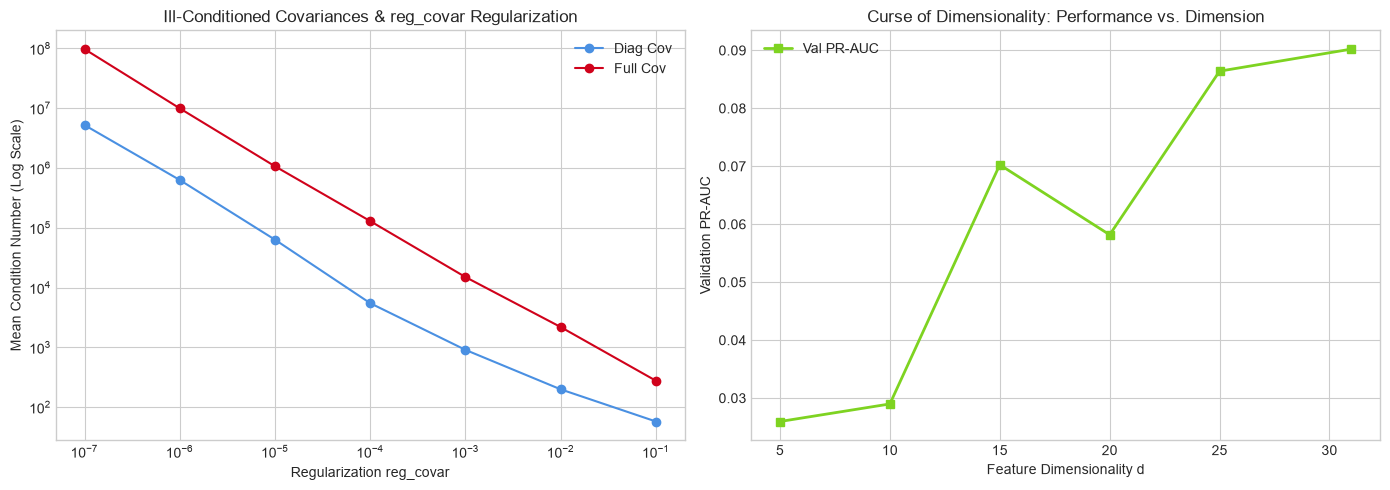

In [12]:
fig_inst, (ax_reg, ax_dim) = plt.subplots(1, 2, figsize=(14, 5))

reg_df = instab['reg_covar_df']
for cov, col in [('diag', '#4A90E2'), ('full', '#D0021B')]:
    sub = reg_df[reg_df['covariance_type'] == cov]
    ax_reg.plot(sub['reg_covar'], sub['mean_condition_number'], marker='o', label=f'{cov.capitalize()} Cov', color=col)
ax_reg.set_xscale('log')
ax_reg.set_yscale('log')
ax_reg.set_xlabel('Regularization reg_covar')
ax_reg.set_ylabel('Mean Condition Number (Log Scale)')
ax_reg.set_title('Ill-Conditioned Covariances & reg_covar Regularization')
ax_reg.legend()

dim_df = instab['dim_df']
ax_dim.plot(dim_df['dimension'], dim_df['val_pr_auc'], marker='s', color='#7ED321', linewidth=2, label='Val PR-AUC')
ax_dim.set_xlabel('Feature Dimensionality d')
ax_dim.set_ylabel('Validation PR-AUC')
ax_dim.set_title('Curse of Dimensionality: Performance vs. Dimension')
ax_dim.legend()

plt.tight_layout()
plt.show()


## 11. Key Empirical Takeaways & Synthesis
1. **Validation Performance:** The GMM baseline achieves a Validation PR-AUC of **0.1950** and a Test PR-AUC of **0.4142** (over $300\times$ the random fraud base rate of $0.0013$).
2. **Operational Triage:** At a tight false-positive budget of $\text{FPR} = 0.5\%$, the model catches **$68.42\%$ of frauds on validation and $69.33\%$ on test**.
3. **Precision@K:** Among the top-50 flagged alerts on test, **$50.0\%$ are actual confirmed frauds**, meaning half of analyst triage time yields direct recovery.
4. **Failure Modes:** Missed frauds exhibit feature coordinates within the $1$-sigma core of the legitimate distribution, demonstrating that statistical density alone cannot detect stealthy micro-charges.
